# Post-training test-set evaluation

This notebook evaluates an already-trained prostate lesion segmentation checkpoint. It does **not** retrain the model. It creates per-volume metrics and visualizations under the configured evaluation directory.

Run the configuration cell first, then run the remaining cells in order. Set `CHECKPOINT_PATH` to the checkpoint you want to evaluate. For a normal single-model evaluation this is usually `saved_weights/best_prostate_unet3d.pth`. If `save_best_checkpoint_alias = False`, select one of the saved fold checkpoints explicitly, for example `saved_weights/cross_validation_fold_1.pth`.

In [1]:
from pathlib import Path
import sys

# Change this only when the notebook is run from outside the repository.
PROJECT_ROOT = Path.cwd().resolve().parent
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError("Could not find the project root containing src/.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import ExperimentConfig

config = ExperimentConfig(base_dir=PROJECT_ROOT)

# Change CHECKPOINT_PATH when comparing another trained checkpoint.
CHECKPOINT_PATH = config.saved_weights_dir / "best_prostate_unet3d.pth"
TEST_DIR = config.test_dir
OUTPUT_DIR = config.evaluation_output_dir
THRESHOLD = 0.5
DEVICE = "cuda"  # Use "cpu" when CUDA is unavailable.

if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {CHECKPOINT_PATH}")
if not TEST_DIR.is_dir():
    raise FileNotFoundError(f"Test directory not found: {TEST_DIR}")
TEST_FILES = sorted(TEST_DIR.glob("*.pkl"))
if not TEST_FILES:
    raise FileNotFoundError(f"No .pkl test volumes found in {TEST_DIR}")

print(f"Project root: {PROJECT_ROOT}")
print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Test volumes: {len(TEST_FILES)}")
print(f"Output directory: {OUTPUT_DIR}")

Project root: /home/robakp/Exeriments1/separate_prostate_detection_training
Checkpoint: /home/robakp/Exeriments1/separate_prostate_detection_training/saved_weights/best_prostate_unet3d.pth
Test volumes: 38
Output directory: /home/robakp/Exeriments1/separate_prostate_detection_training/evaluation


In [2]:
import torch
from src.utils.evaluation import generate_evaluation_artifacts

if DEVICE == "cuda" and not torch.cuda.is_available():
    print("CUDA is unavailable; using CPU instead.")
    device = torch.device("cpu")
else:
    device = torch.device(DEVICE)

config.generate_evaluation_artifacts = False
config.evaluation_threshold = THRESHOLD
config.evaluation_output_dir = OUTPUT_DIR
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

metrics_path = generate_evaluation_artifacts(
    config=config,
    checkpoint=CHECKPOINT_PATH,
    test_files=TEST_FILES,
    device=device,
)
print(f"Evaluation complete: {metrics_path}")

Evaluation complete: /home/robakp/Exeriments1/separate_prostate_detection_training/evaluation/test_case_metrics.csv


In [3]:
import pandas as pd
from IPython.display import display

metrics = pd.read_csv(metrics_path)
numeric_metrics = metrics.select_dtypes(include="number")
summary = numeric_metrics.describe().T[["mean", "50%", "std", "min", "max"]]
summary = summary.rename(columns={"50%": "median"})
display(summary.style.format("{:.4f}"))
display(metrics.head())

/home/robakp/Exeriments1/separate_prostate_detection_training/.venv/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/robakp/Exeriments1/separate_prostate_detection_training/.venv/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:4653: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/home/robakp/Exeriments1/separate_prostate_detection_training/.venv/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/robakp/Exeriments1/separate_prostate_detection_training/.venv/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:4653: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


,mean,median,std,min,max
case_id,1426.0526,992.5000,1220.3936,4.0000,3358.0000
dice,0.3109,0.2373,0.3336,0.0000,1.0000
precision,0.2921,0.1717,0.3325,0.0000,1.0000
recall,0.4173,0.3045,0.4257,0.0000,1.0000
hd95_mm,inf,24.4105,nan,0.0000,inf
assd_mm,inf,8.8553,nan,0.0000,inf
target_volume_mm3,1064.8842,315.8400,1679.5890,0.0000,7179.2000
prediction_volume_mm3,1595.8821,952.0000,1643.3119,0.0000,5642.5600
relative_volume_error,0.9880,1.0000,1.2376,-0.8708,5.6212
false_positive_voxels,435.6842,330.0000,480.3145,0.0000,2357.0000


,case_id,dice,precision,recall,hd95_mm,assd_mm,target_volume_mm3,prediction_volume_mm3,relative_volume_error,false_positive_voxels,false_negative_voxels,ground_truth_has_lesion,prediction_has_lesion
0,4,0.764036,0.78853,0.741018,2.884441,0.912951,5985.28,5624.64,-0.060254,531.0,692.0,1,1
1,22,0.000000,0.00000,0.000000,inf,inf,0.00,67.20,1.000000,30.0,0.0,0,1
2,86,0.000000,0.00000,0.000000,inf,inf,0.00,127.68,1.000000,57.0,0.0,0,1
3,1019,0.000000,0.00000,0.000000,56.330468,33.753153,2271.36,293.44,-0.870809,131.0,1014.0,1,1
4,1144,0.000000,0.00000,0.000000,inf,inf,0.00,459.20,1.000000,205.0,0.0,0,1


In [4]:
detection_metrics = pd.read_csv(OUTPUT_DIR / "patient_detection_metrics.csv")
display(detection_metrics.style.format({"value": "{:.4f}"}))

print("Specificity is the fraction of truly lesion-free patients correctly predicted as lesion-free.")

,metric,value
0,total_patients,38.0000
1,lesion_positive_patients,22.0000
2,lesion_negative_patients,16.0000
3,true_positive_patients,22.0000
4,false_positive_patients,14.0000
5,true_negative_patients,2.0000
6,false_negative_patients,0.0000
7,patient_sensitivity,1.0000
8,patient_specificity,0.1250
9,patient_accuracy,0.6316


Specificity is the fraction of truly lesion-free patients correctly predicted as lesion-free.


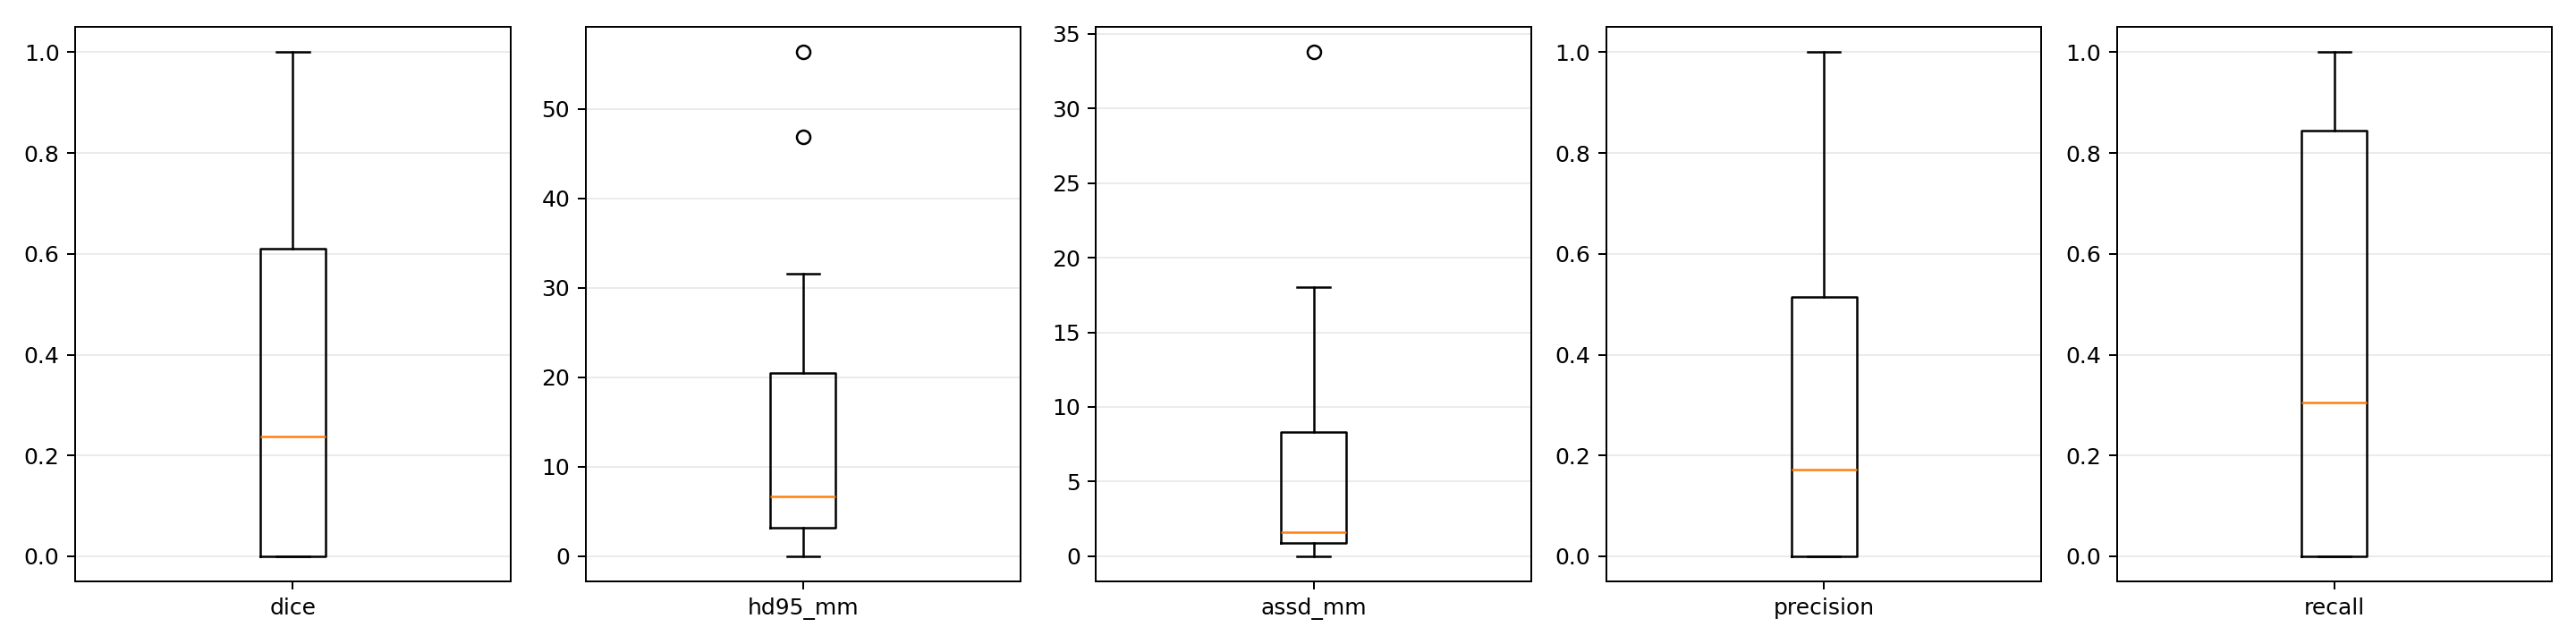

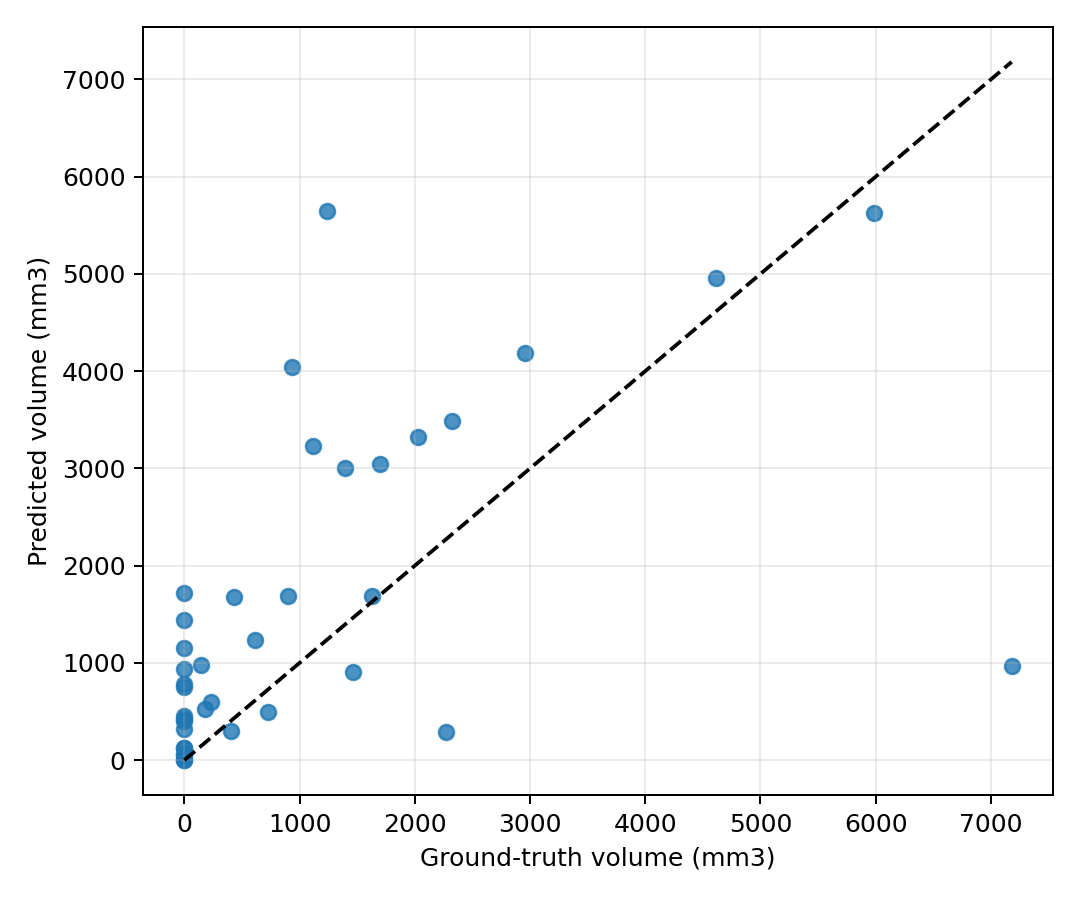

In [5]:
from IPython.display import Image, display

for filename in ("test_metric_distributions.png", "volume_agreement.png"):
    path = OUTPUT_DIR / filename
    if path.is_file():
        display(Image(filename=str(path), width=1000))
    else:
        print(f"Missing expected figure: {path}")

022_views.png


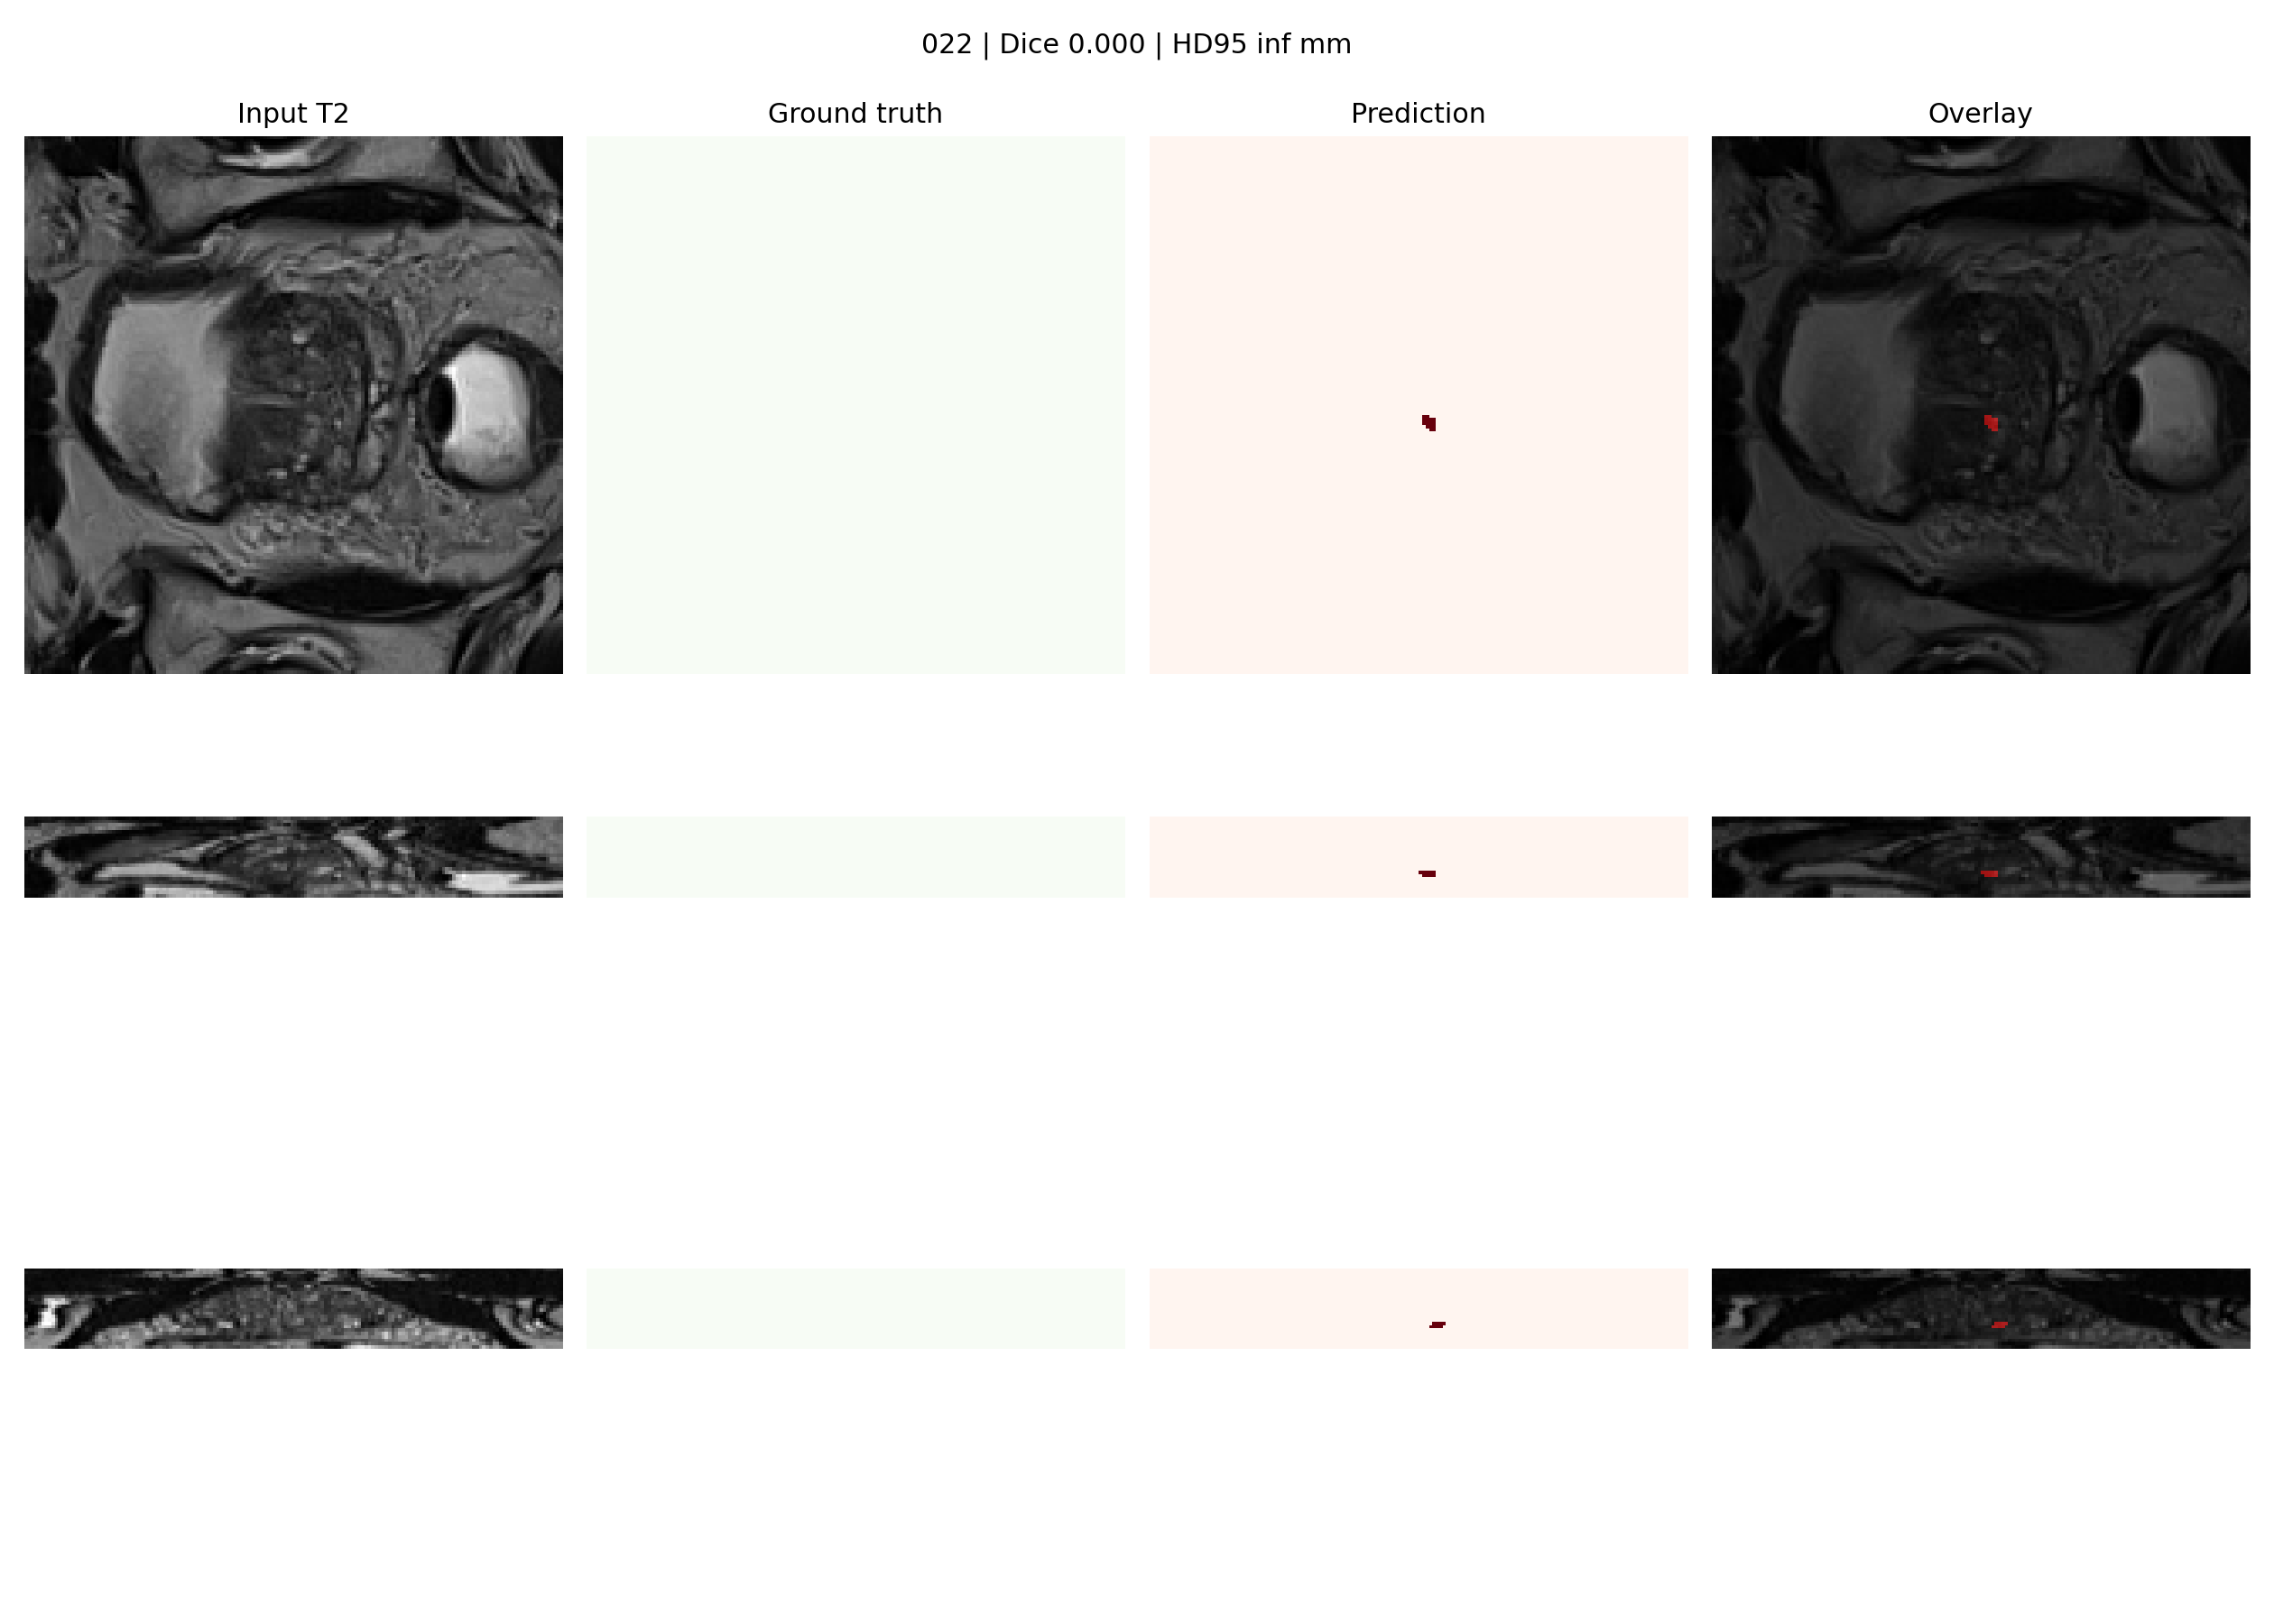

1019_views.png


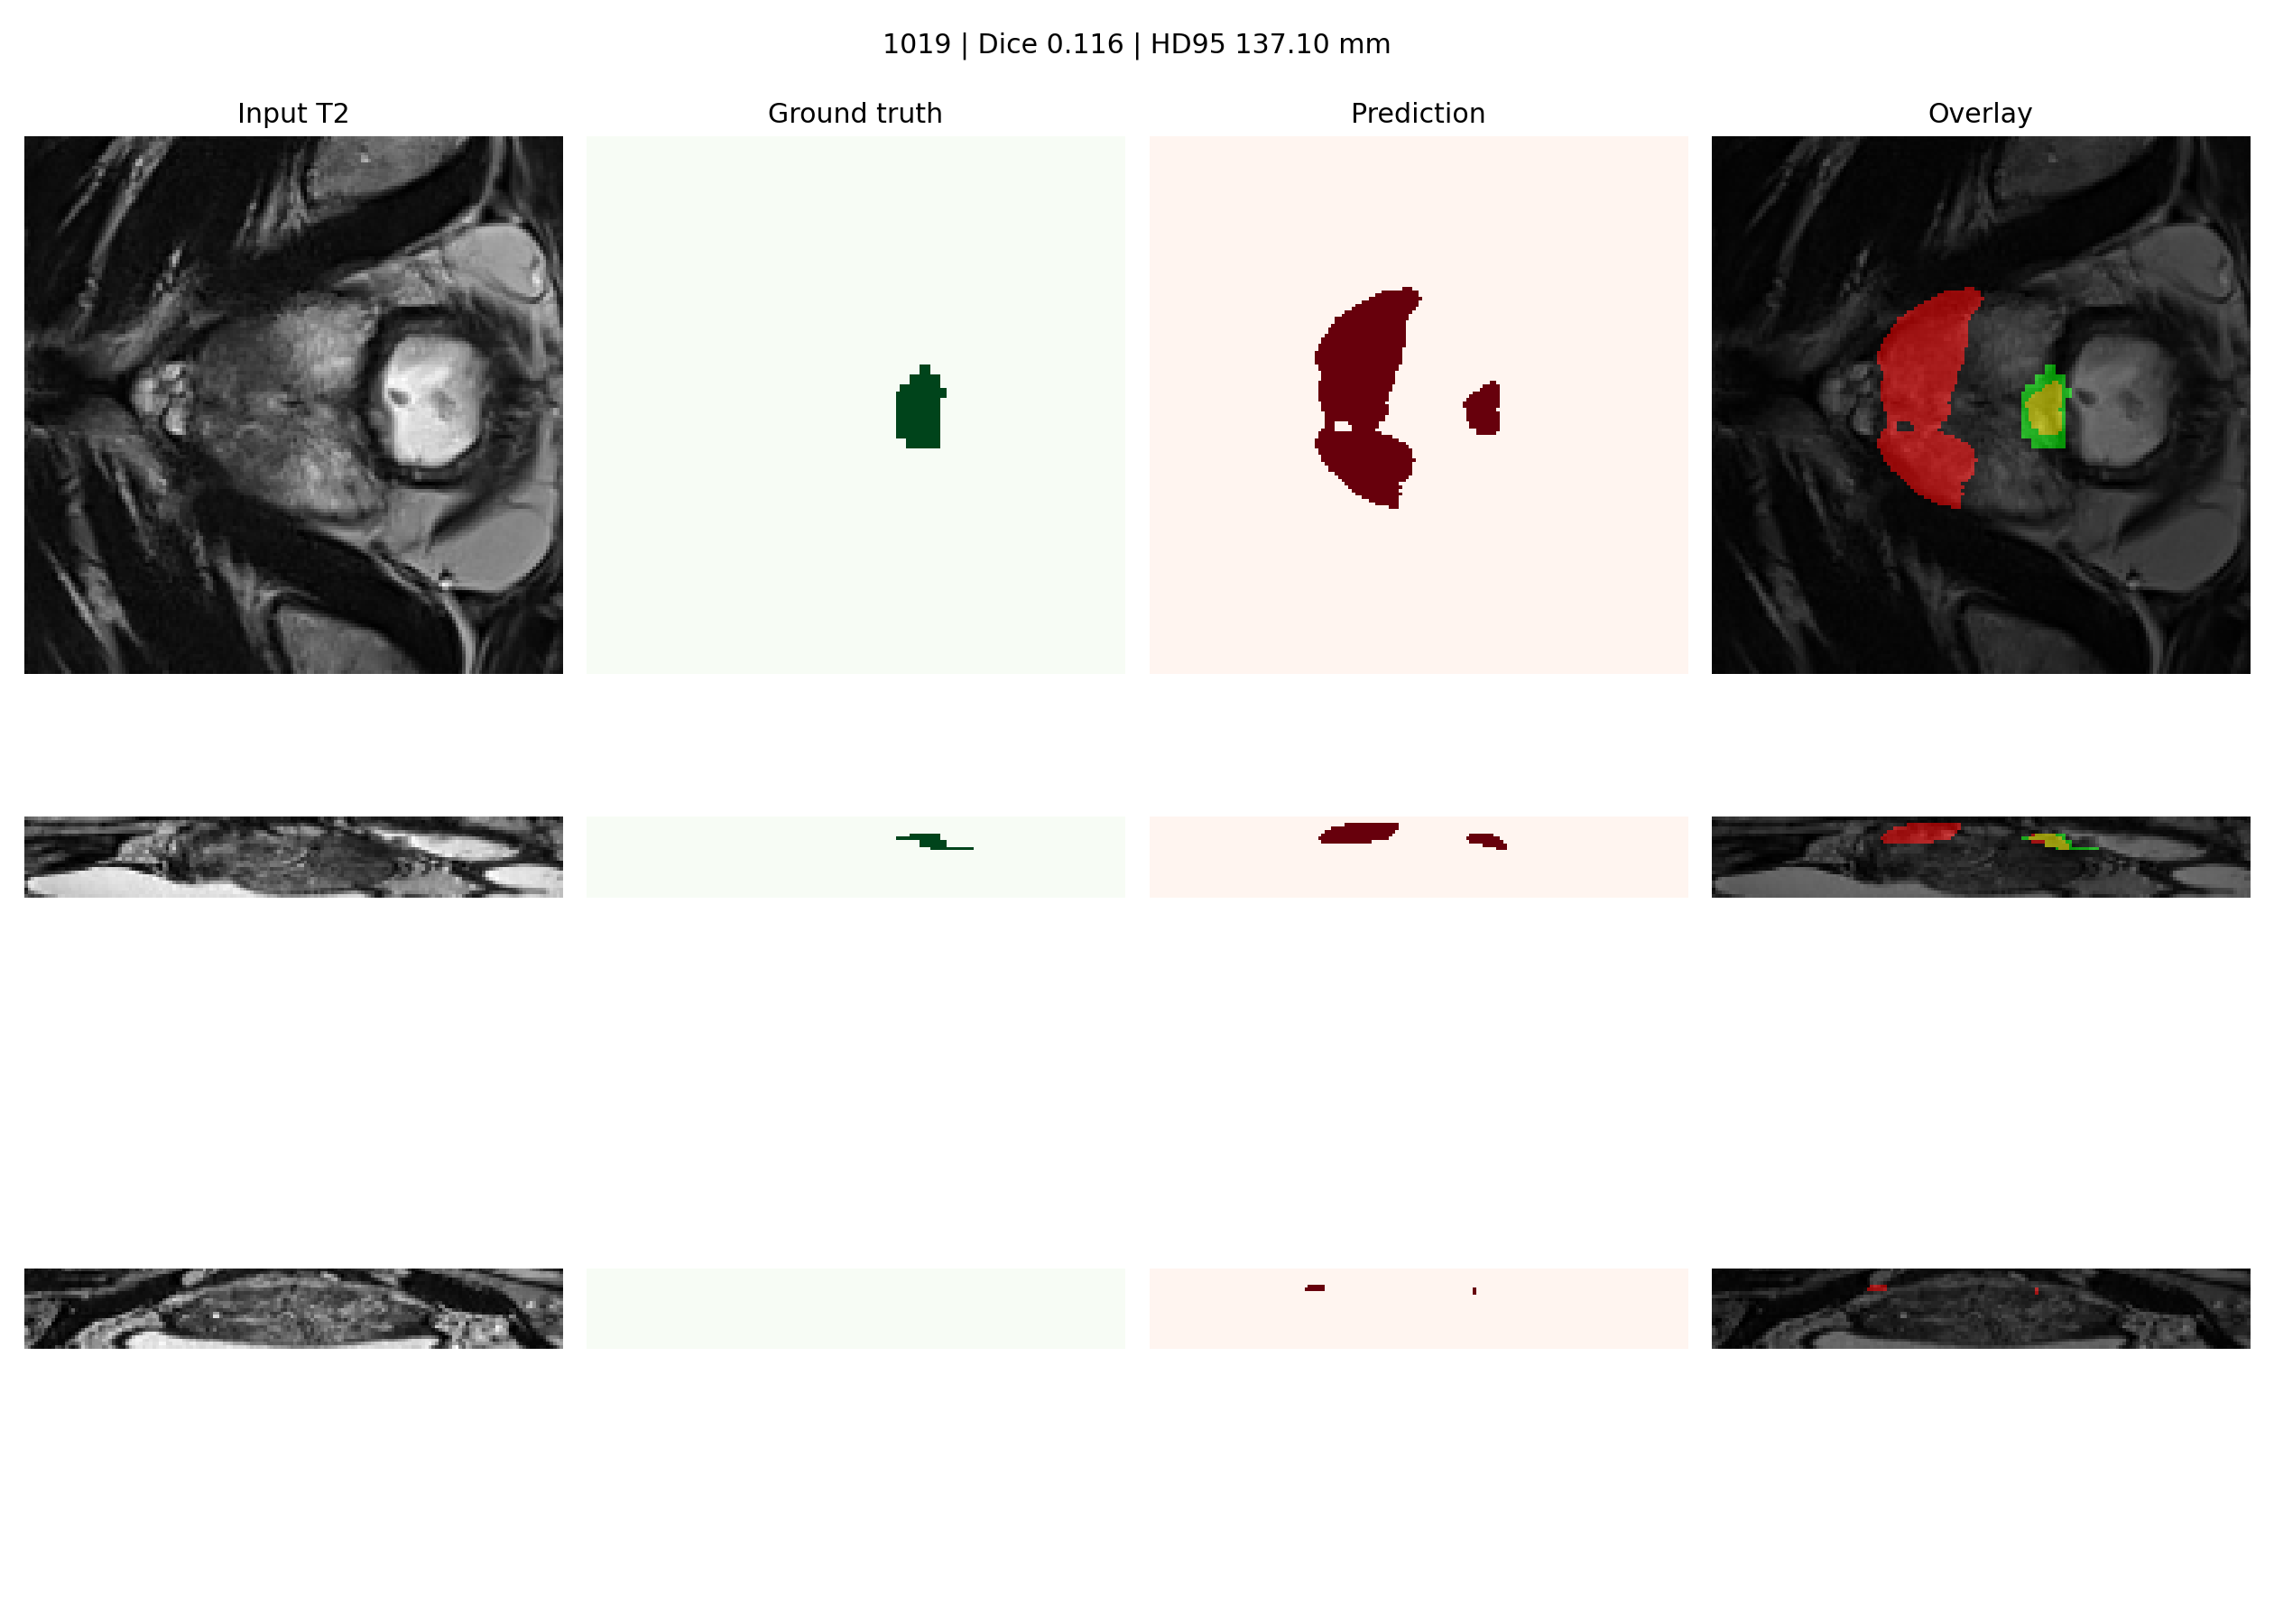

3083_views.png


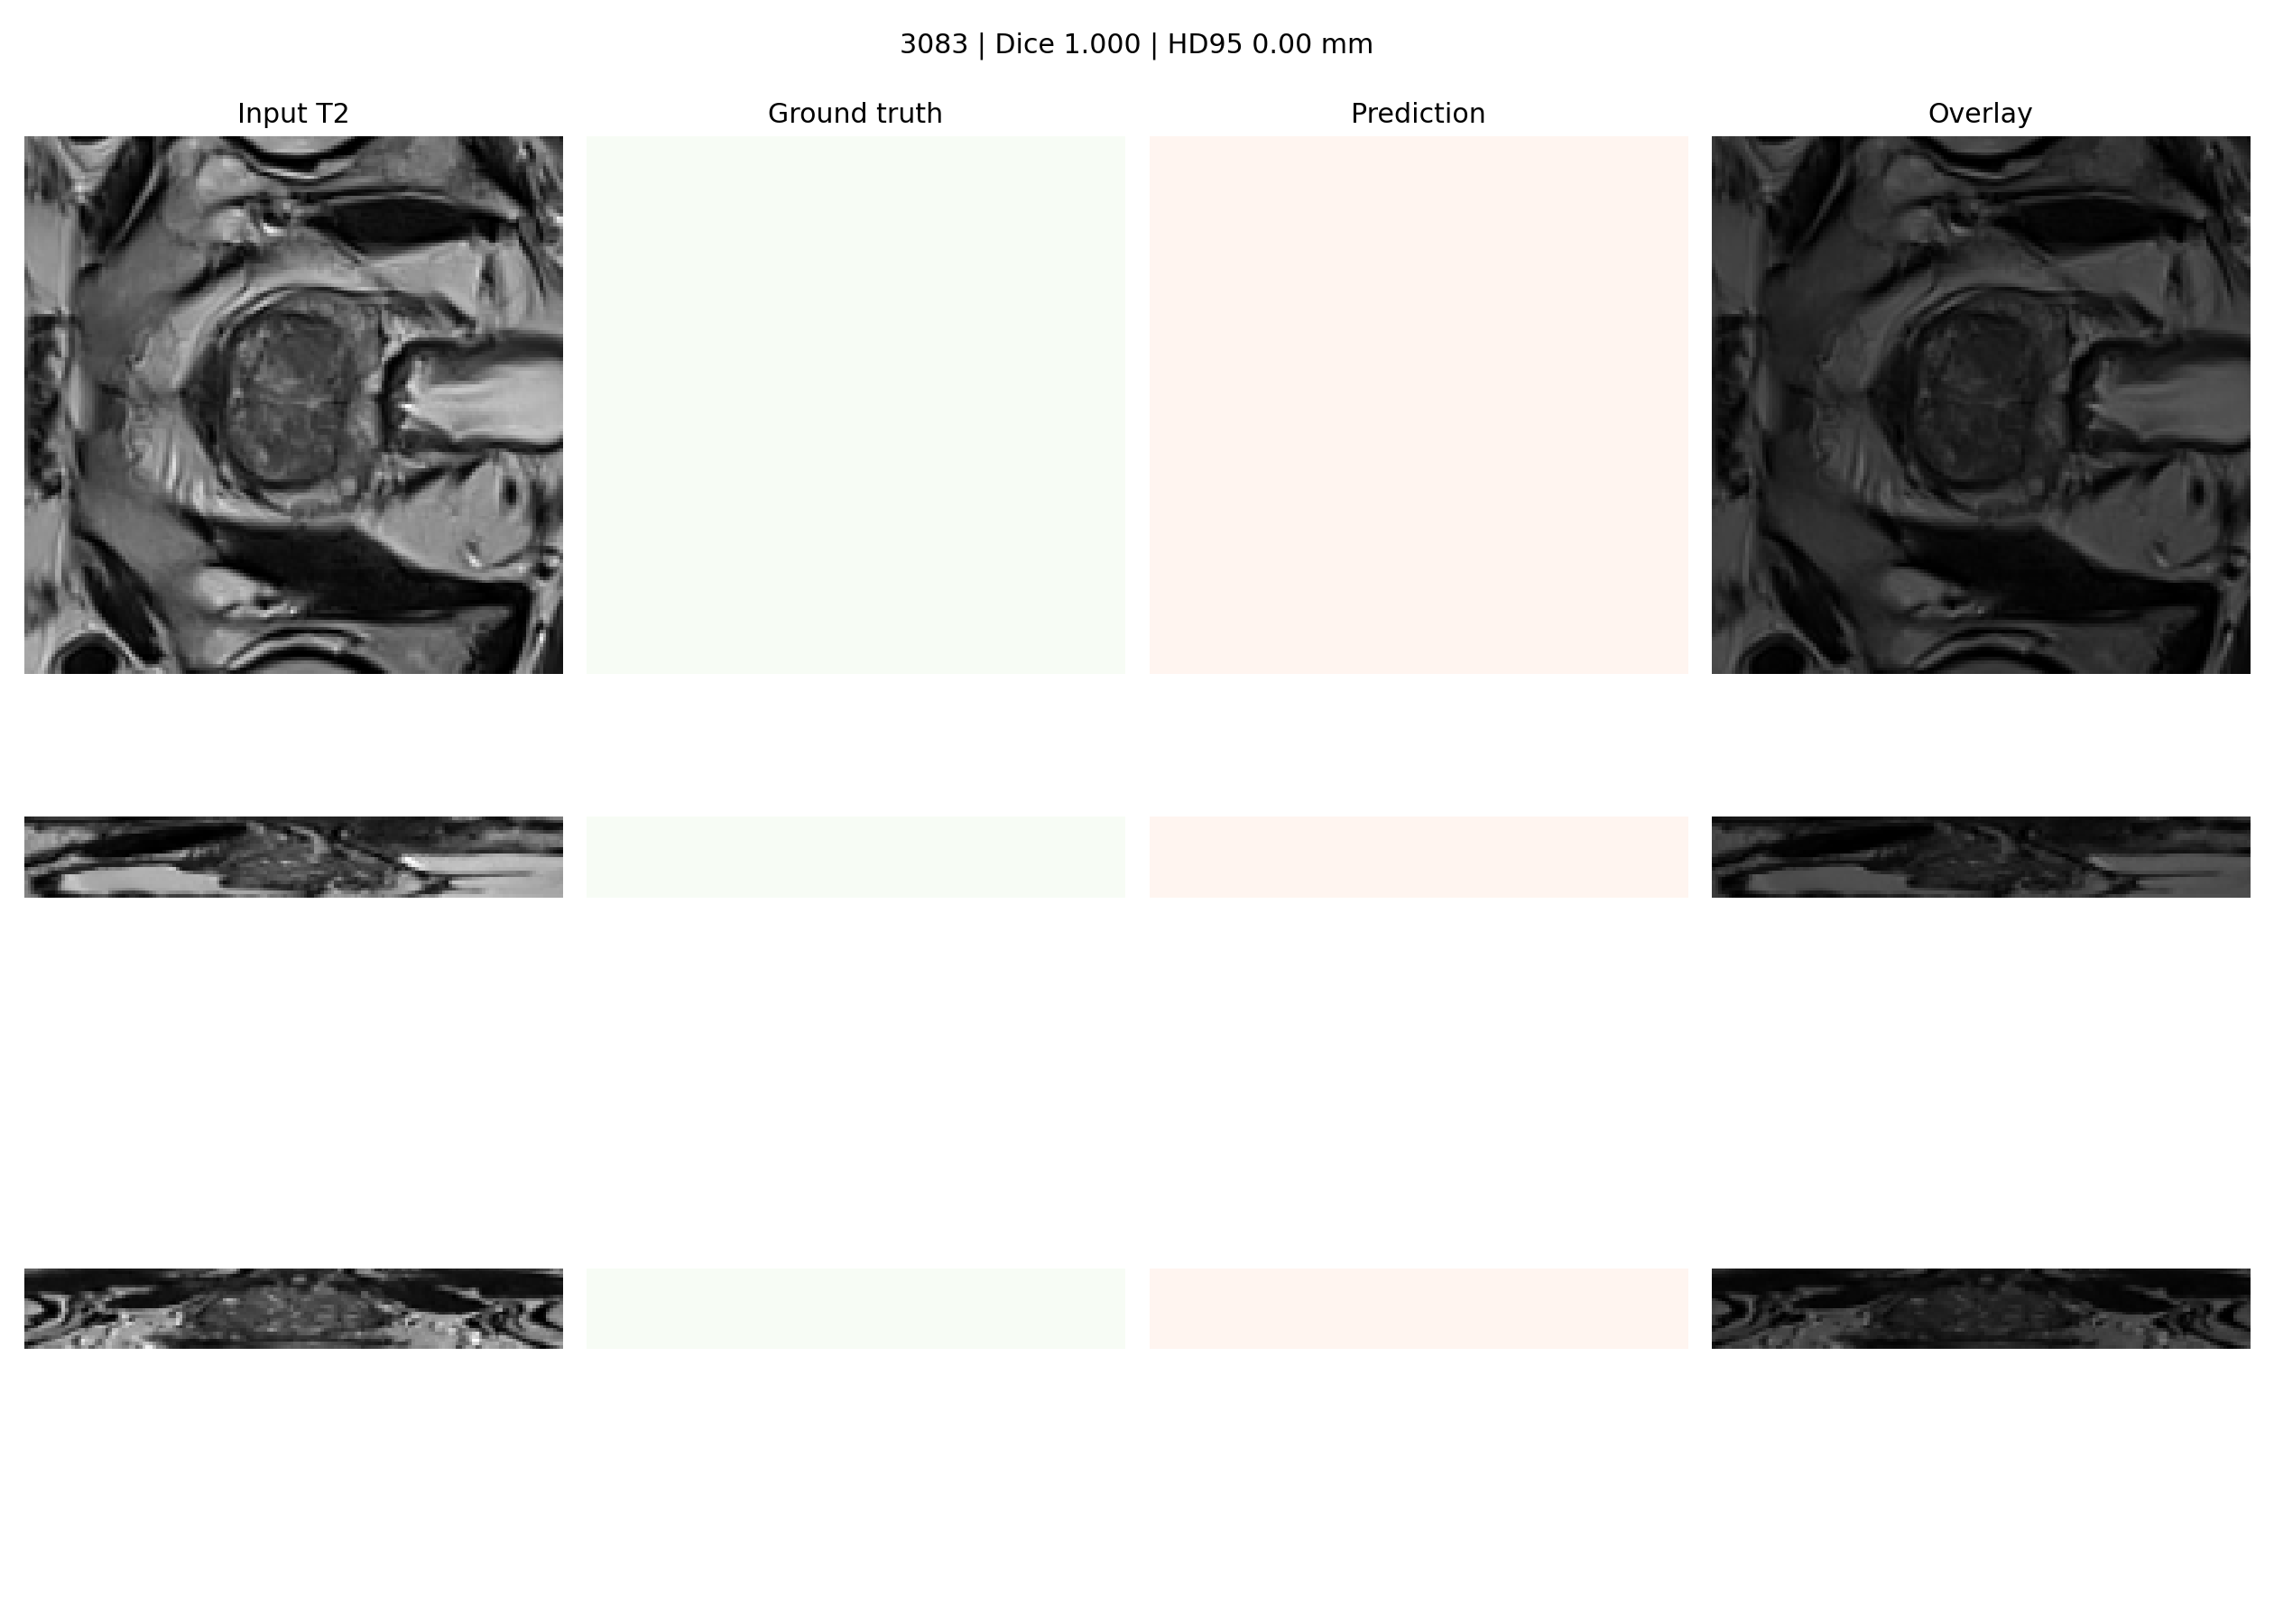

3358_views.png


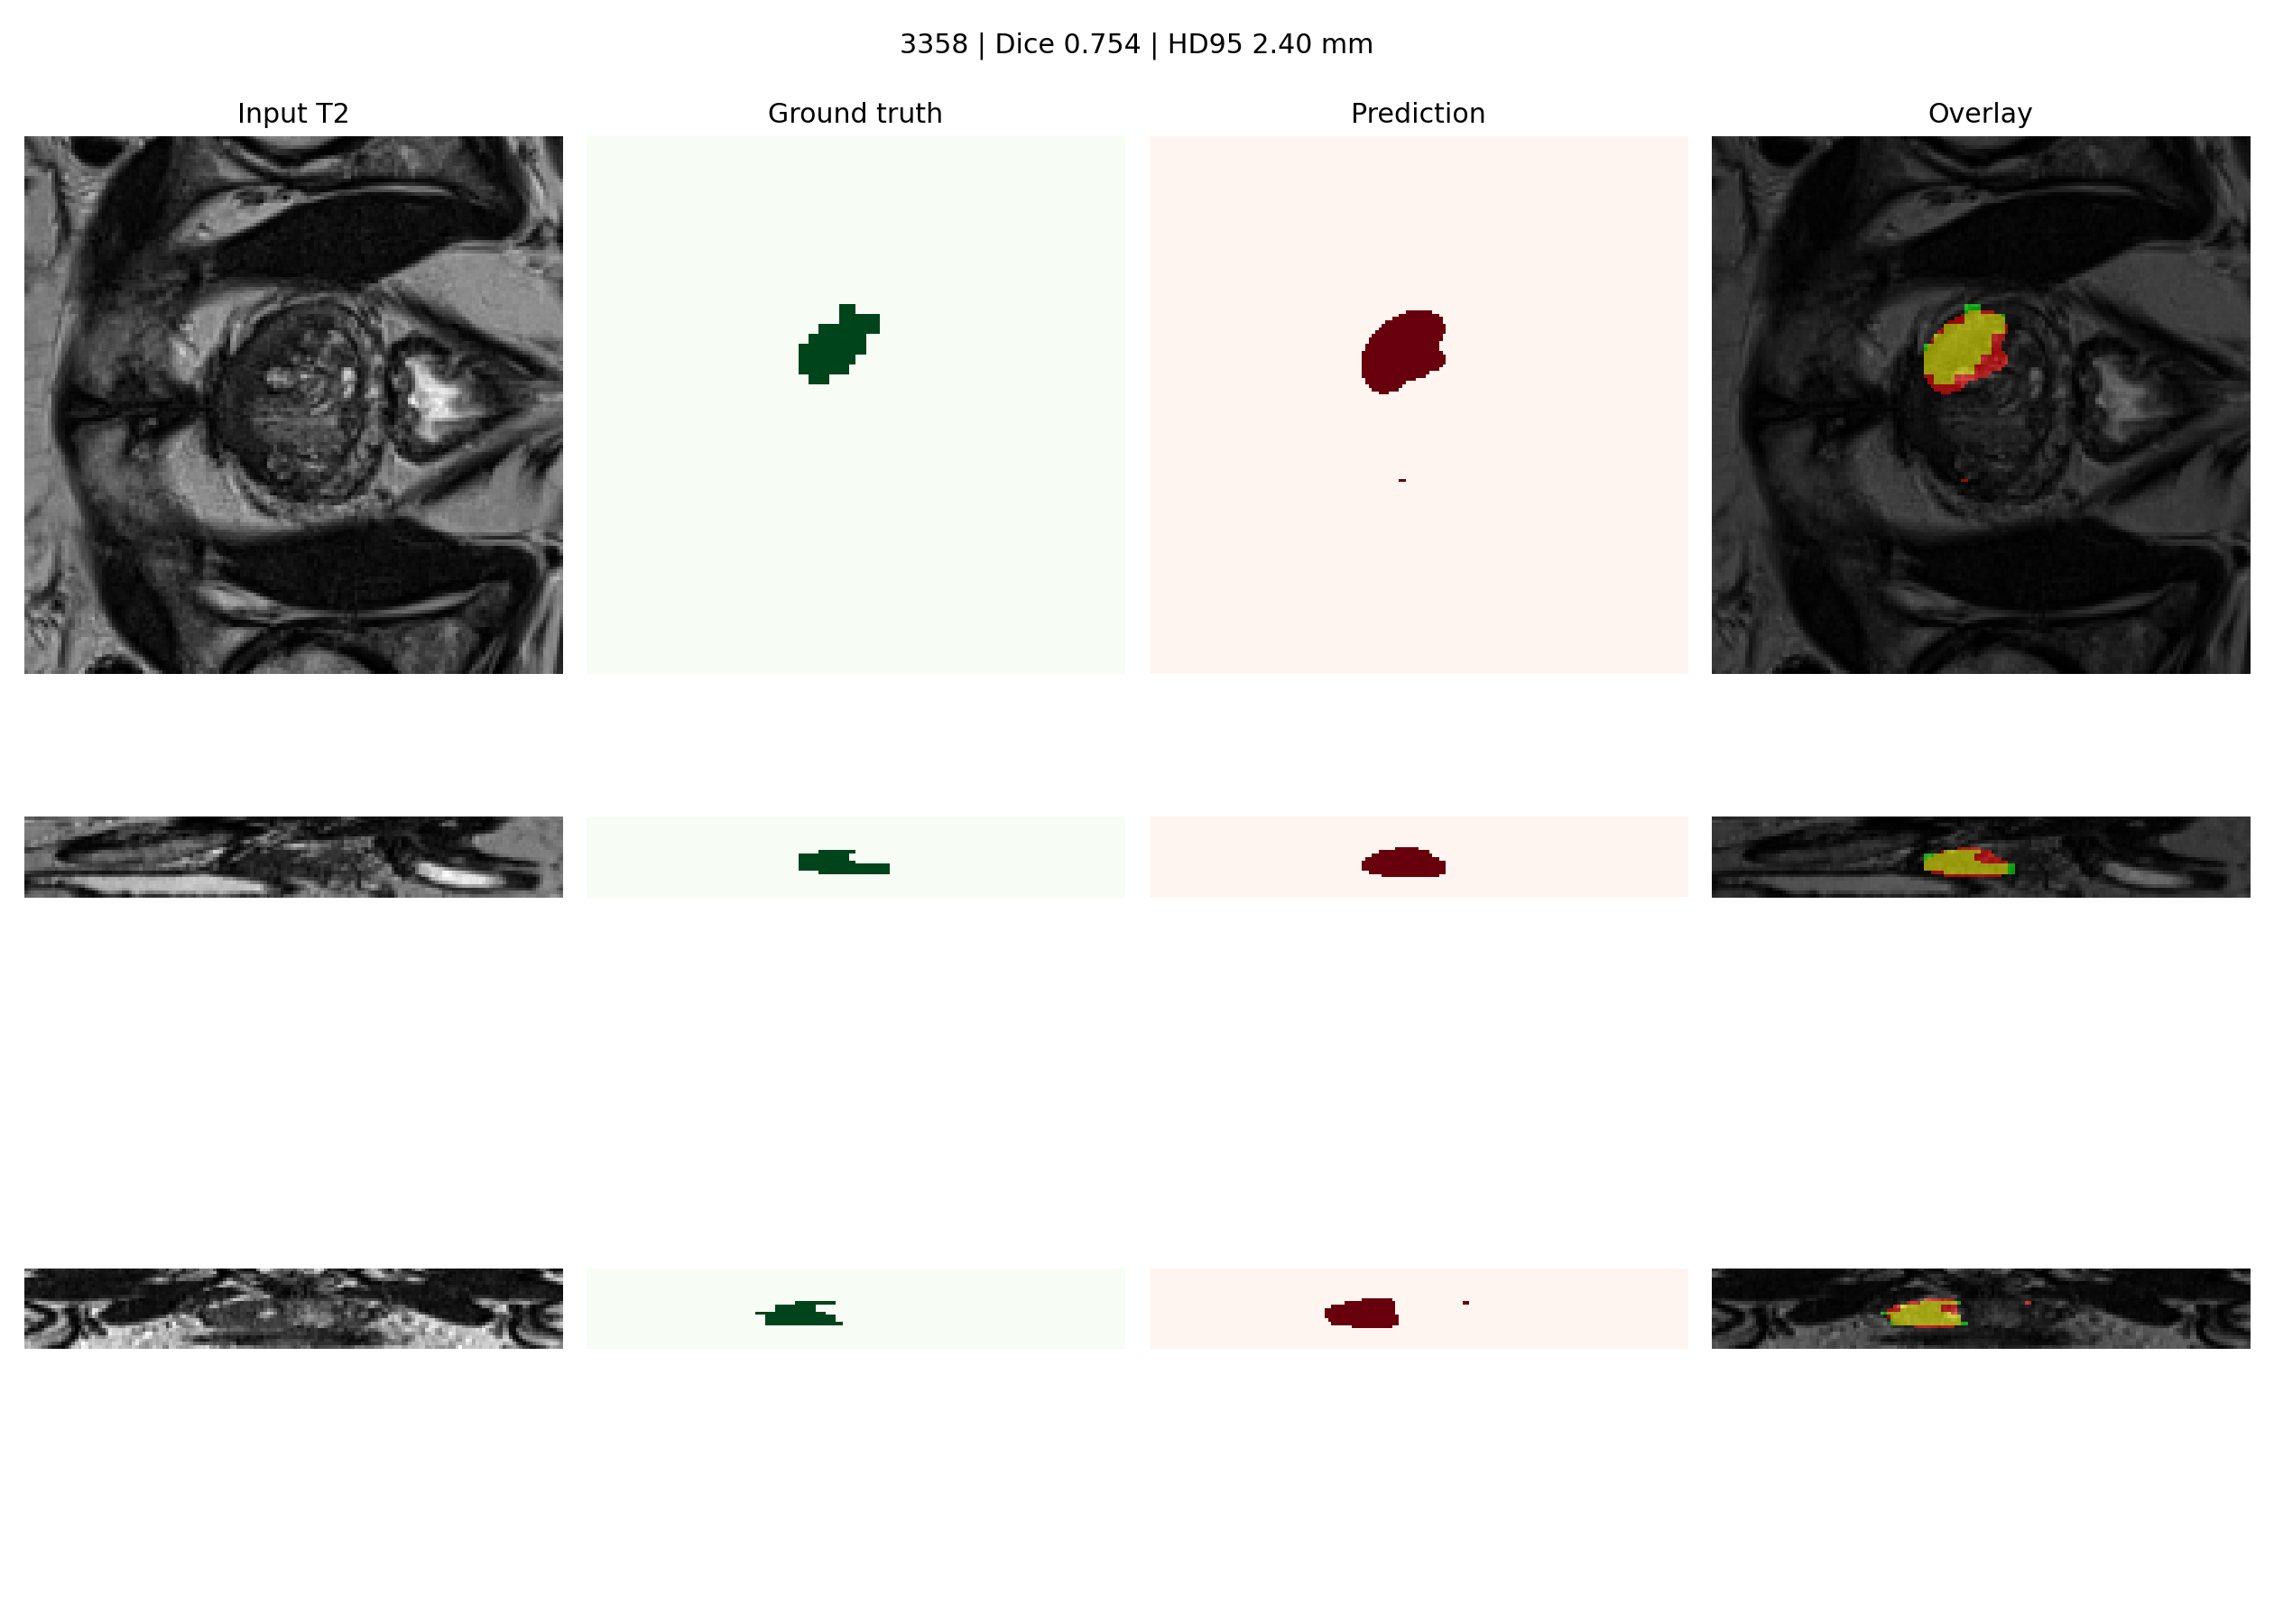

706_views.png


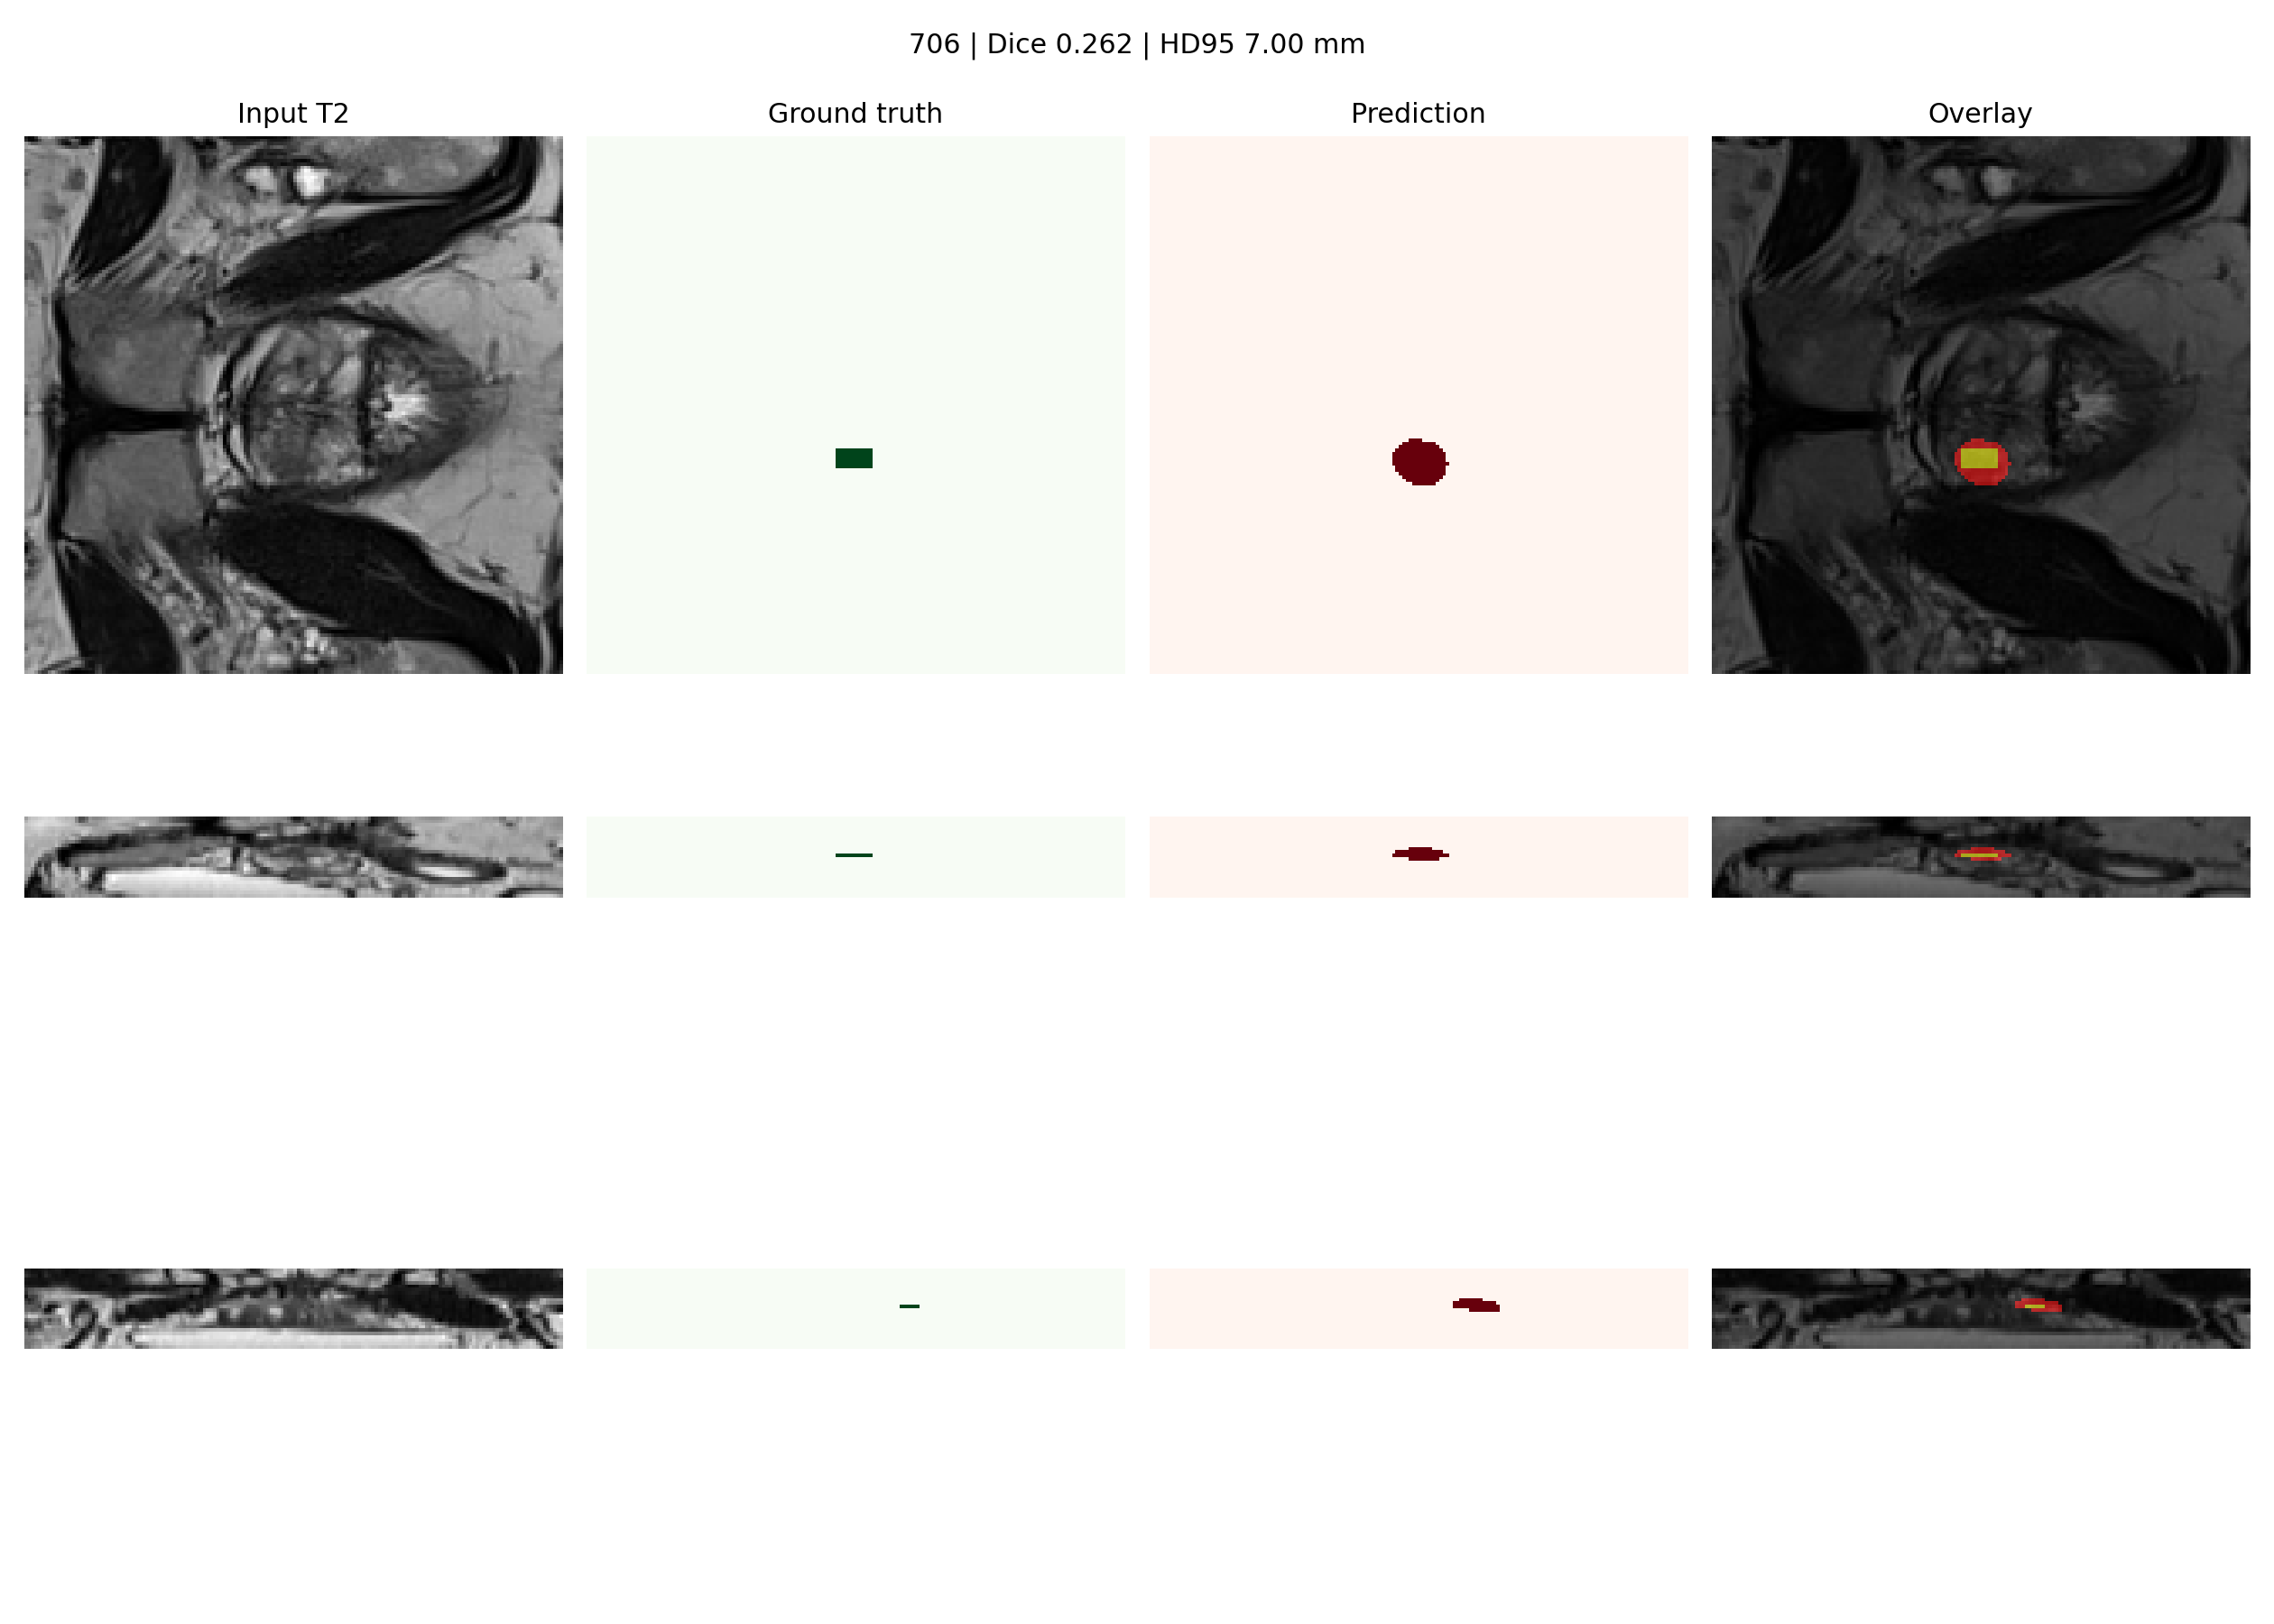

1019_surface_error.png


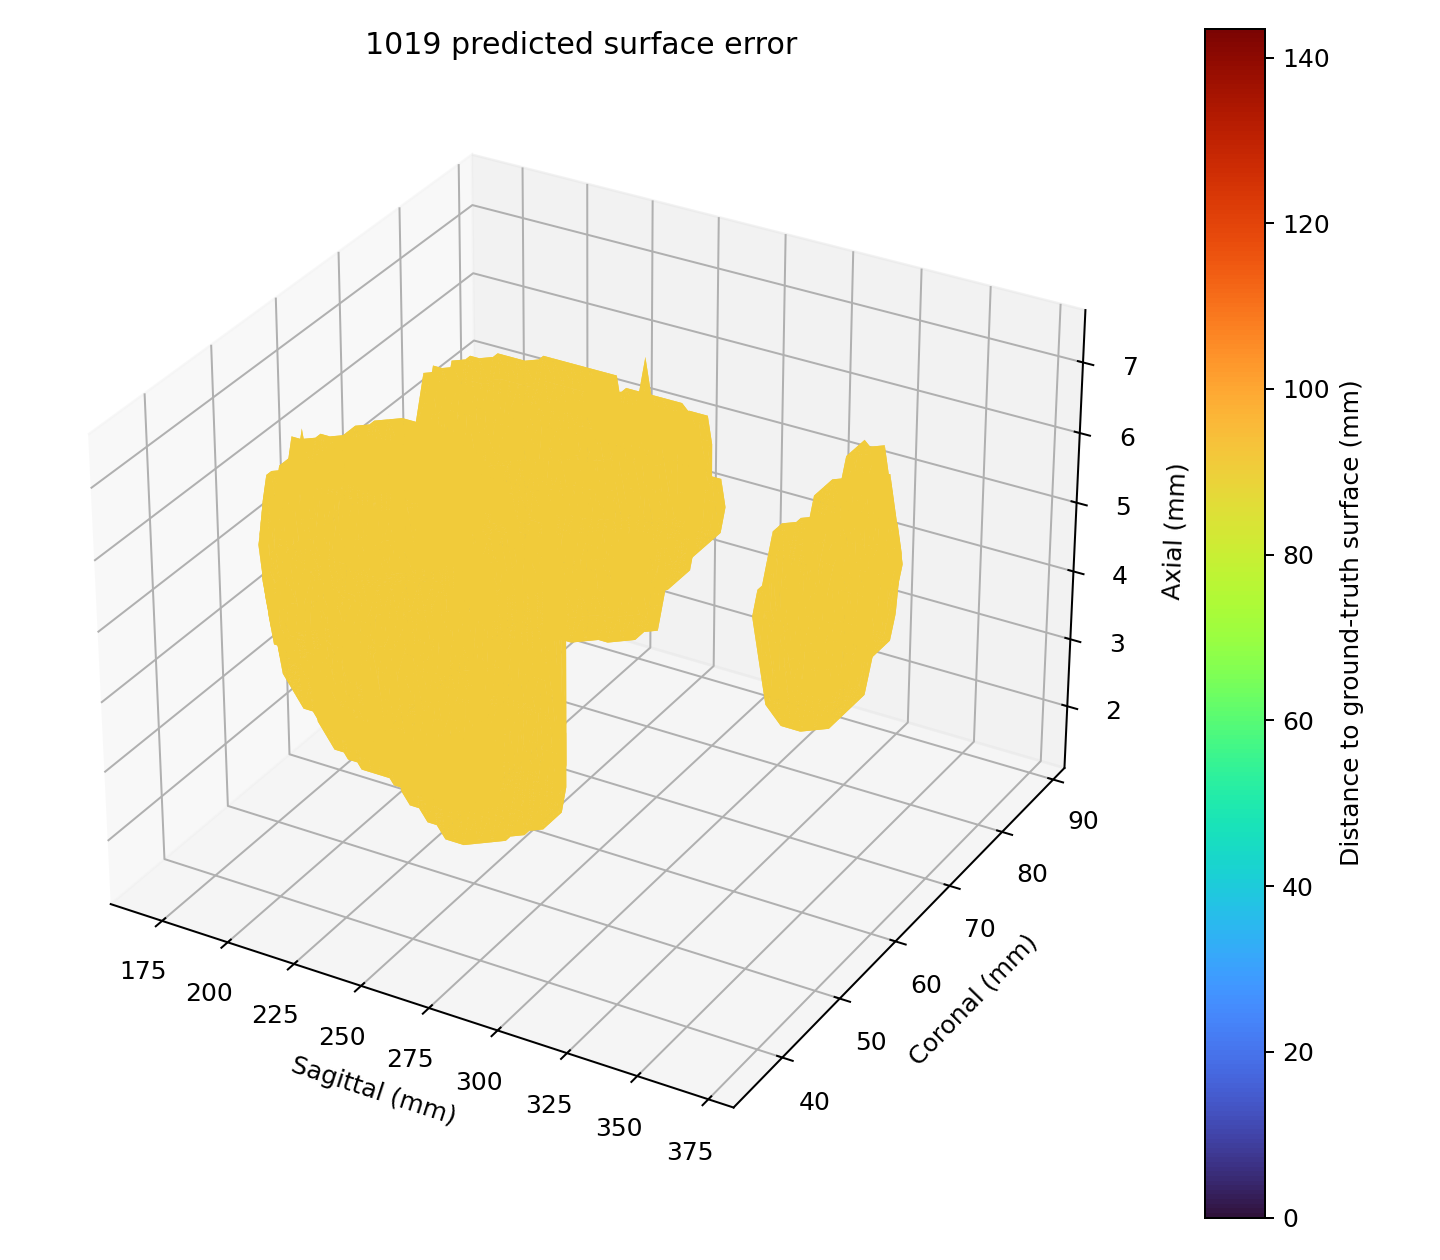

3358_surface_error.png


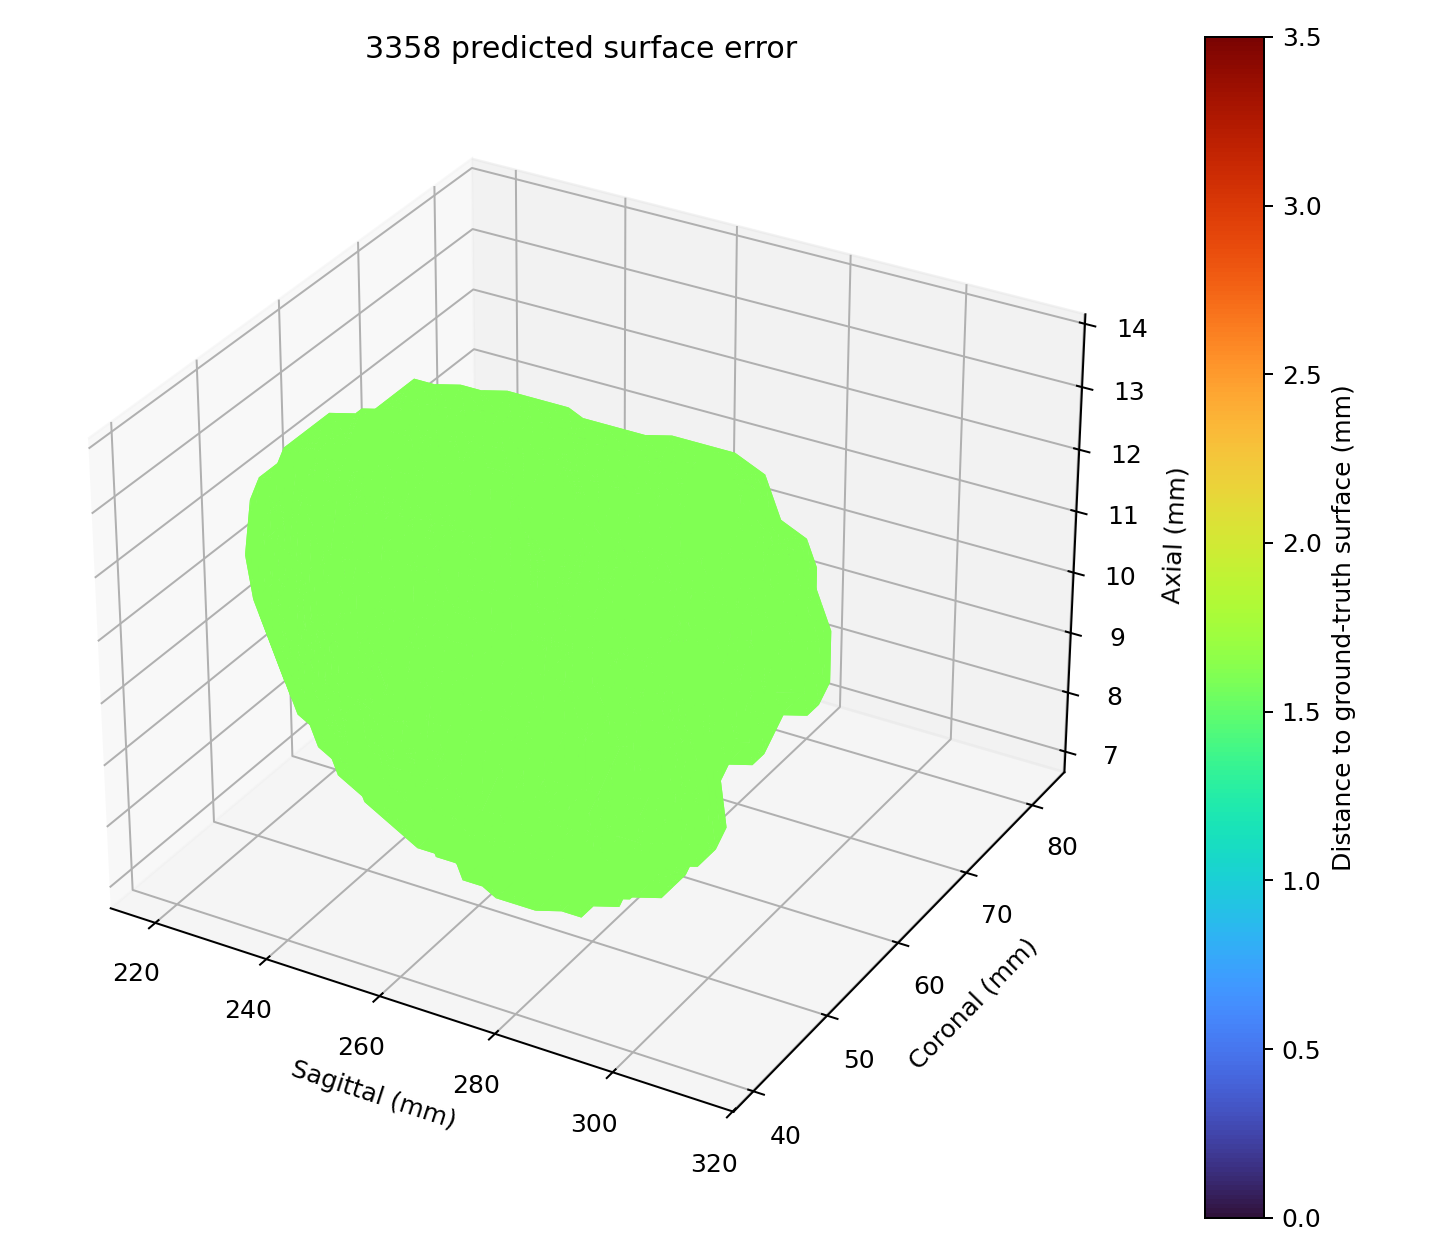

706_surface_error.png


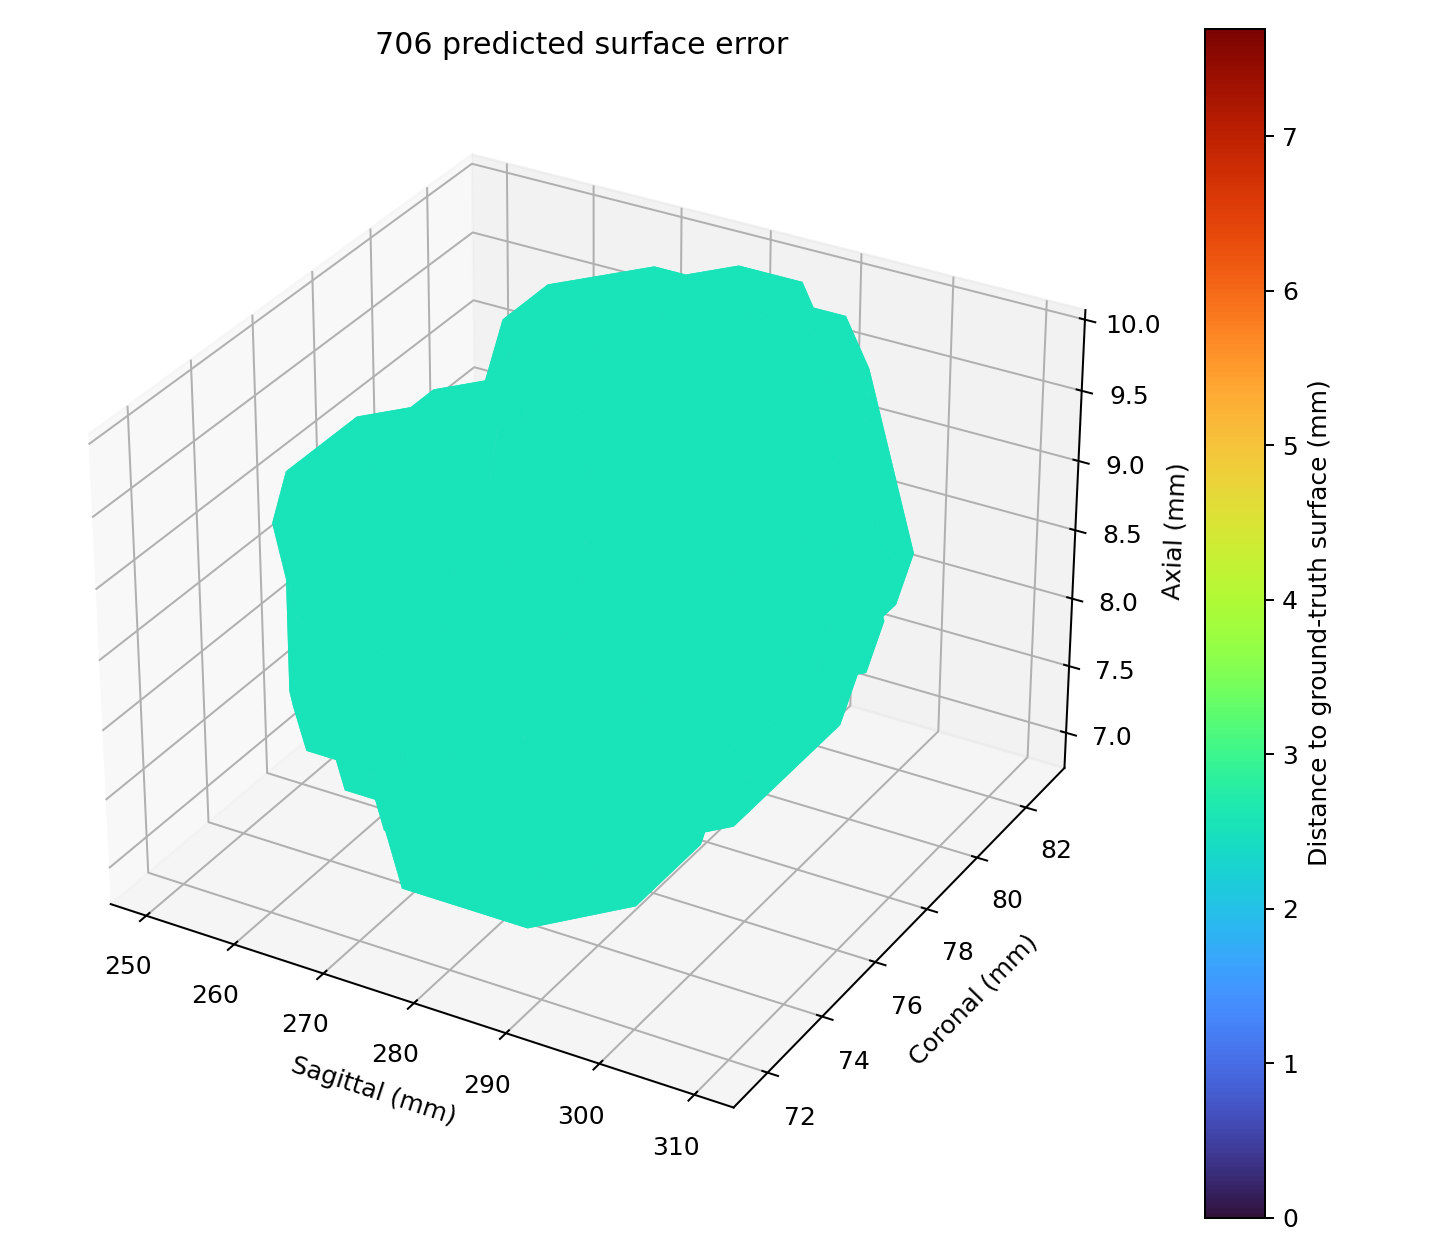

In [6]:
from IPython.display import Image, display

# The evaluator writes best, median, and worst Dice cases.
view_files = sorted(OUTPUT_DIR.glob("*_views.png"))
surface_files = sorted(OUTPUT_DIR.glob("*_surface_error.png"))
for path in view_files:
    print(path.name)
    display(Image(filename=str(path), width=1000))
for path in surface_files:
    print(path.name)
    display(Image(filename=str(path), width=800))

## Interactive prediction viewer

Run this cell to inspect every slice for any test case. Use the case, view, and slice controls to compare the input, ground truth, prediction, and overlay. Enable **Focus on overlay** to hide the other panels and enlarge the combined overlay. Ground truth is green and prediction is red.


In [ ]:
from src.utils.evaluation import show_prediction_viewer

show_prediction_viewer(
    config=config,
    checkpoint=CHECKPOINT_PATH,
    test_files=TEST_FILES,
    device=device,
)

## Notes


- `HD95` and `ASSD` are reported in millimetres using `config.target_spacing`.
- The threshold should be selected using validation data, not tuned on the held-out test set.
- To evaluate another checkpoint, change `CHECKPOINT_PATH`, restart or rerun the configuration and evaluation cells, and use a different `OUTPUT_DIR` if you want to preserve the previous results.
- The notebook uses the existing implementation in `src/utils/evaluation.py`, so its results match the post-training evaluation invoked by `main.py`.